# Benchmark metrics

Inputs: `results/metrics/<variant>/` (run_metrics_pipeline.sh). 

Plots: `results/plots/<variant>/metrics_*`. 

Unit = configuration; 95% CI from a (hierarchical) bootstrap. Titles only in PNG.

In [1]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from metrics import summary
from utils import batch
from utils import constants as cons
from viz.figures import save_figure
from viz.labels import model_labels
from viz.metric_plots import plot_metric_bars
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [2]:
# Parameters
SMOKE = False                                   # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # analysis variant: config/variants/<VARIANT>.yaml (main: config/analysis.yaml)
ADJUSTED = True                               # social metrics size-adjusted: <metric>_adj = observed - expected (random recommender)
MODELS = None                                  # None = all models with metrics
N_BOOT = cons.DEFAULT_BOOTSTRAP_SAMPLES
SAVE = True
FORMATS = ['pdf']                              # e.g. ['png', 'pdf']
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
from utils import analysis_config
V = analysis_config.notebook_variant(VARIANT, SMOKE)  # folders + config of the variant (configure_variant.py)

In [3]:
# Data: one row per configuration, with the model characteristics
METRICS_DIR = Path(V['metrics_dir'])
PLOTS_DIR = Path(V['plots_dir'])
configs = summary.with_model_attributes(summary.configuration_table(METRICS_DIR, MODELS))
models = [m for m in batch.read_models(cons.DEFAULT_MODELS_FILE) if m in set(configs[cons.COL_MODEL])]
print(f"{len(models)} models | {len(configs):,} configurations")

43 models | 92,880 configurations


In [4]:
# Helper: estimate + figure (+ save as metrics_<columns>_<rows> if SAVE and save: the paper figures); columns: a name of cons.METRIC_COLUMN_SETS
# ('paper' = the paper's columns, 'all', 'technical', 'factuality', 'technical_factuality', 'social', 'parity', 'diversity', ...) or metric keys
def metric_figure(rows, columns, rows_name, title=None, save=False):
    columns = summary.adjusted_selection(columns, ADJUSTED)          # e.g. 'paper' -> 'paper_adj'
    metrics = summary.select_metrics(columns)
    table = summary.estimate(configs, rows, metrics, n_boot=N_BOOT)
    fig = plot_metric_bars(table, rows, metrics, title=title)
    if SAVE and save:
        name, adjusted = summary.split_adjusted(columns)               # _adj at the end: metrics_paper_models_adj
        save_figure(fig, f"metrics_{name}_{rows_name}" + ('_adj' if adjusted else ''), PLOTS_DIR, FORMATS)
    return table

## 1. Per model

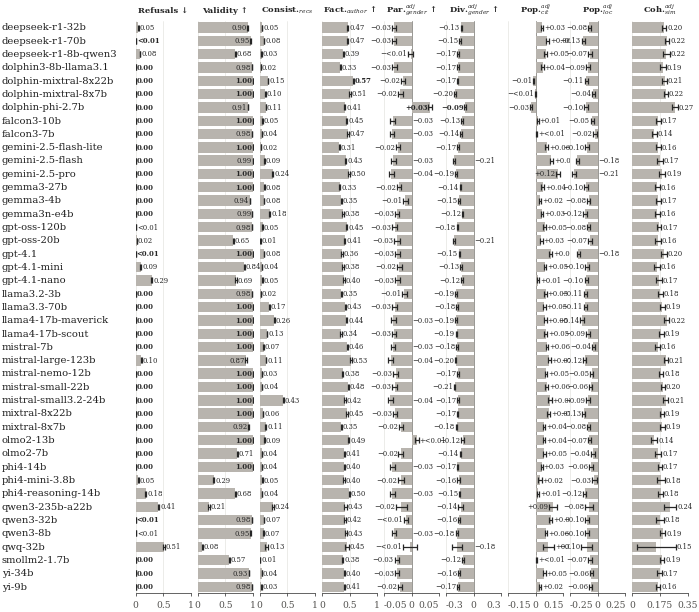

In [5]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
table = metric_figure(summary.model_rows(models, model_labels(models)), 'paper', 'models', save=True)

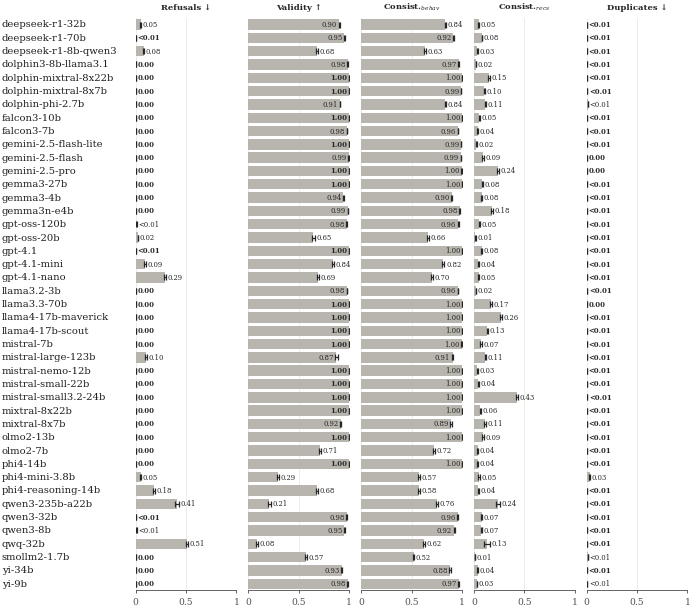

In [6]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'technical', 'models')

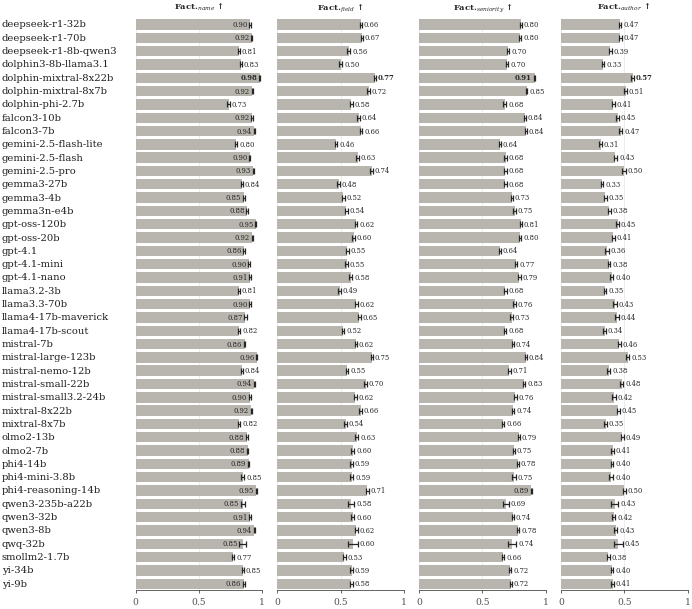

In [7]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'factuality', 'models')

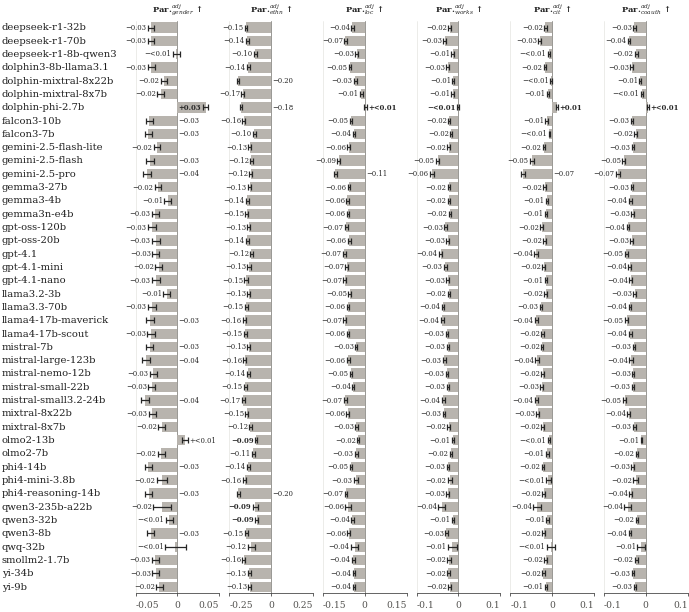

In [8]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'parity', 'models')

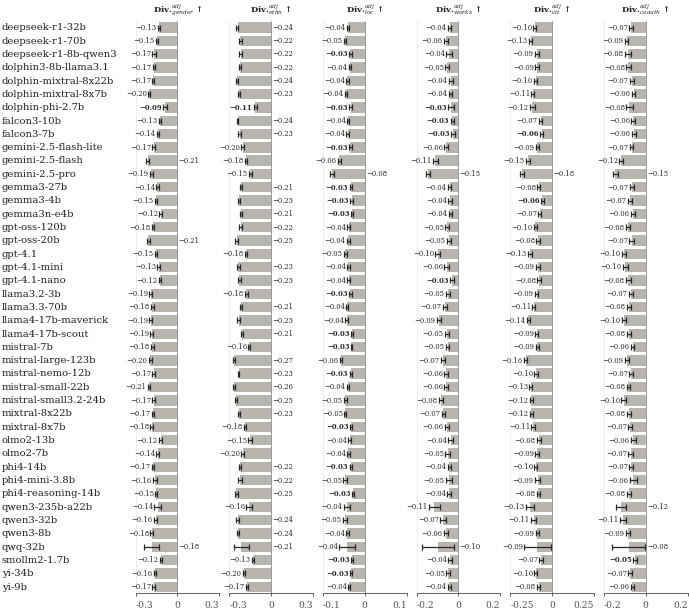

In [9]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'diversity', 'models')

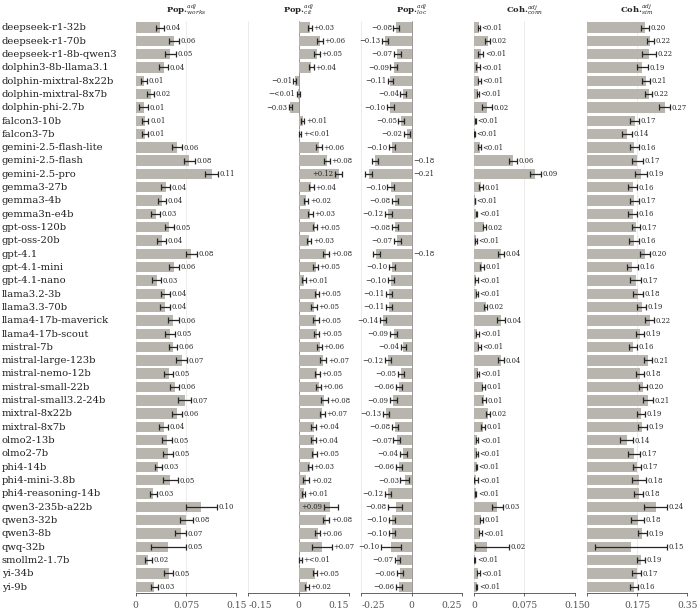

In [10]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'popularity_cohesion_locality', 'models')

## 1b. Per model family

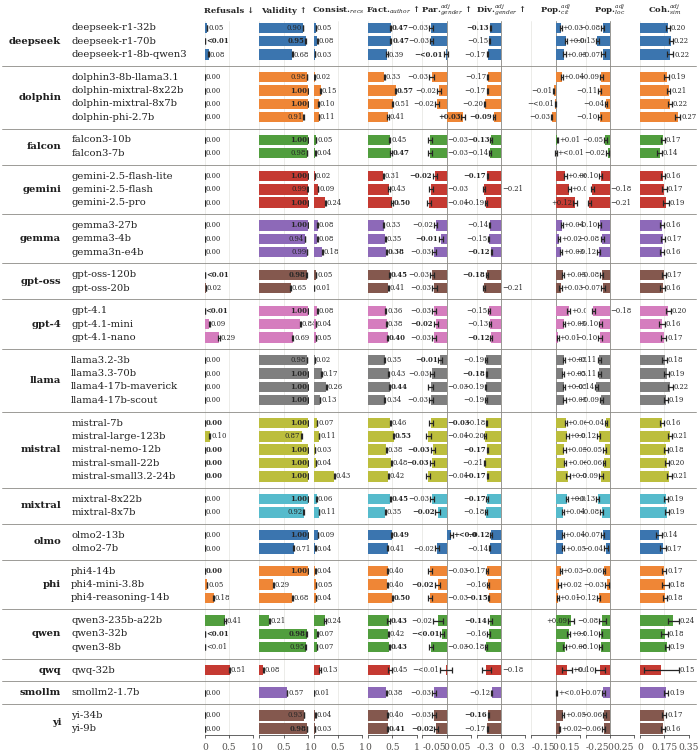

In [11]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
families = summary.model_family_rows(models, labels=model_labels(models))
table = metric_figure(families, 'paper', 'model_families', save=True)

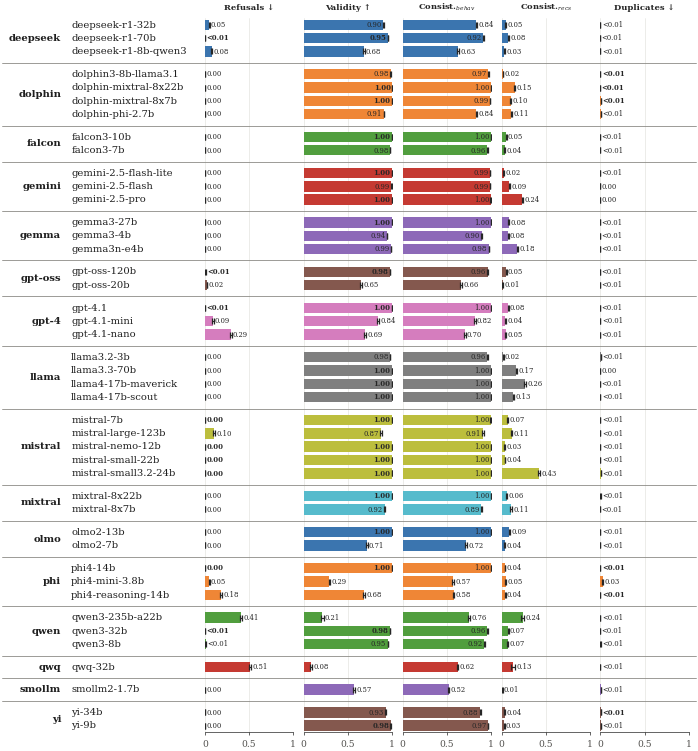

In [12]:
# Rows: models grouped by family (data/models/metadata.json), one colour per family
families = summary.model_family_rows(models, labels=model_labels(models))
table = metric_figure(families, 'technical', 'model_families')

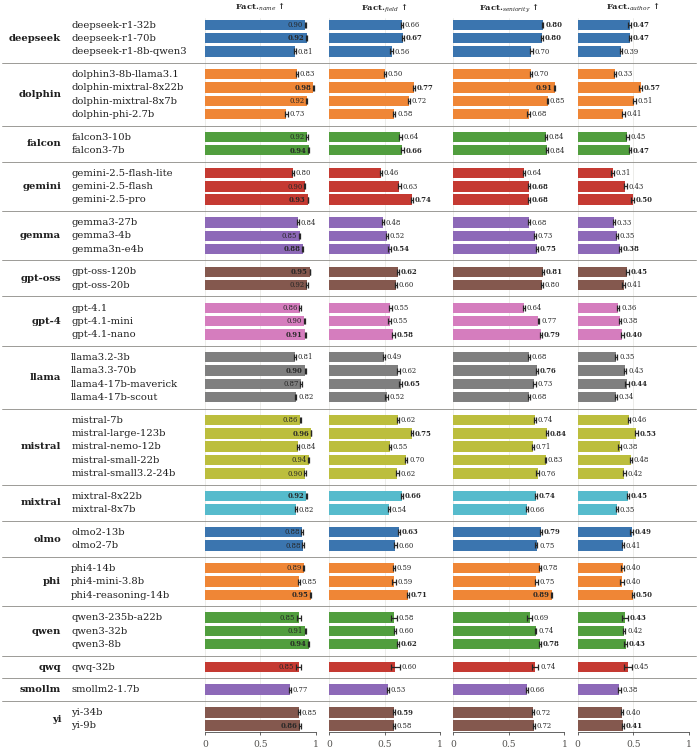

In [13]:
# Rows: models grouped by family (data/models/metadata.json), one colour per family
families = summary.model_family_rows(models, labels=model_labels(models))
table = metric_figure(families, 'factuality', 'model_families')

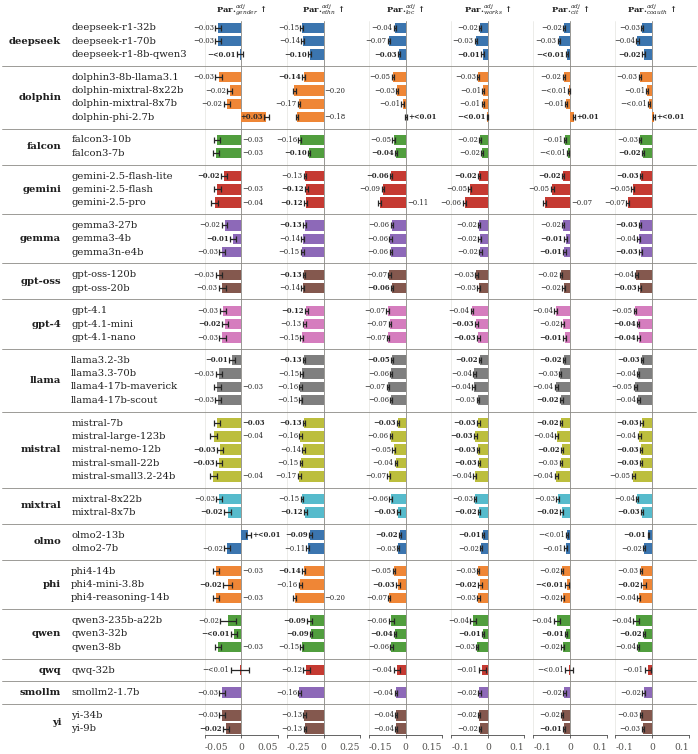

In [14]:
table = metric_figure(families, 'parity', 'model_families')

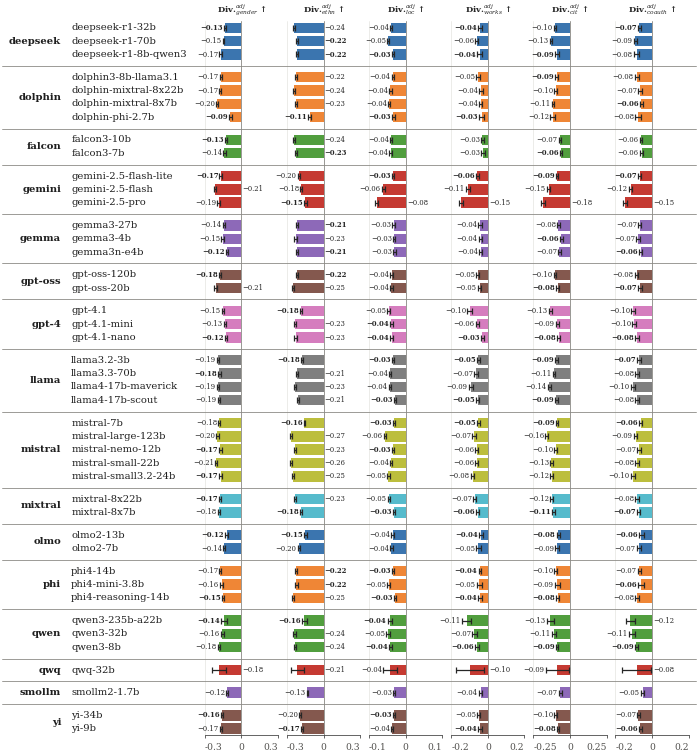

In [15]:
table = metric_figure(families, 'diversity', 'model_families')

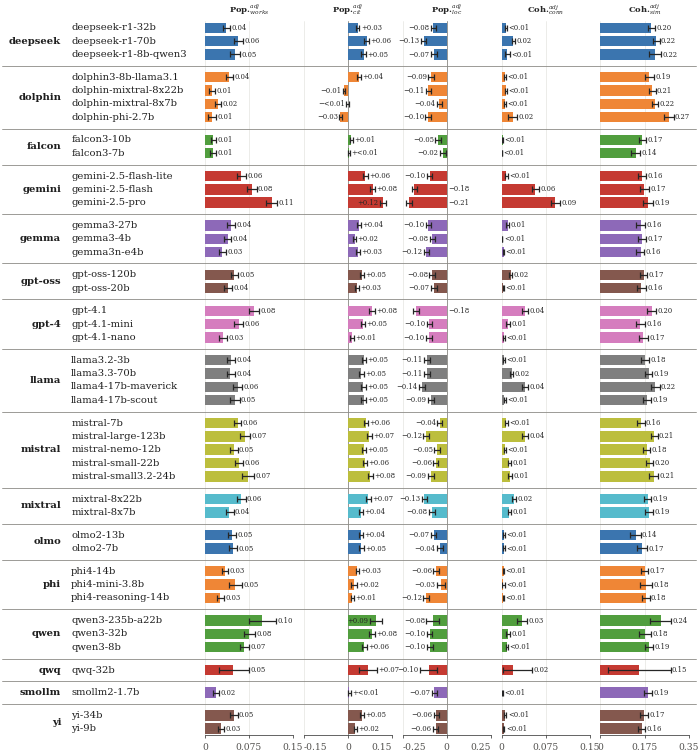

In [16]:
table = metric_figure(families, 'popularity_cohesion_locality', 'model_families')

## 2. By model characteristics

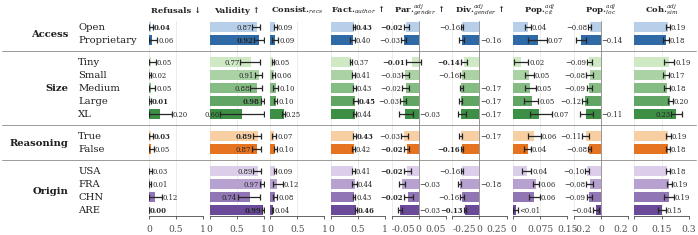

In [17]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
table = metric_figure(summary.attribute_rows(), 'paper', 'model_characteristics', save=True)

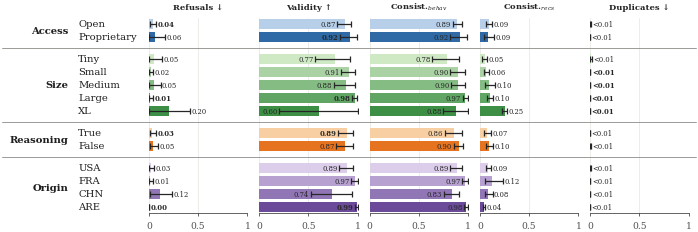

In [18]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'technical', 'model_characteristics')

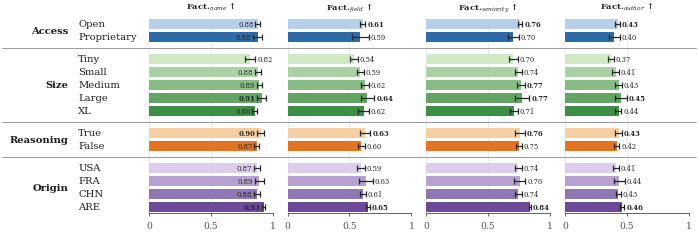

In [19]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'factuality', 'model_characteristics')

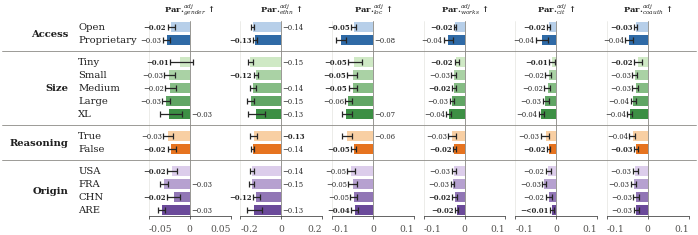

In [20]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'parity', 'model_characteristics')

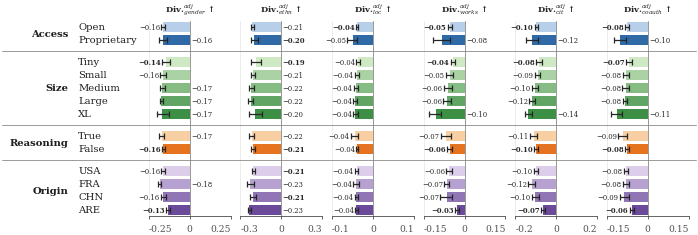

In [21]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'diversity', 'model_characteristics')

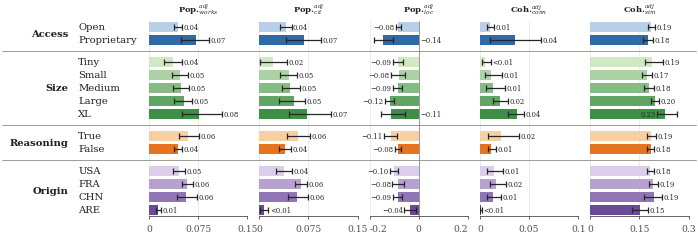

In [22]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'popularity_cohesion_locality', 'model_characteristics')

## 3. By prompt

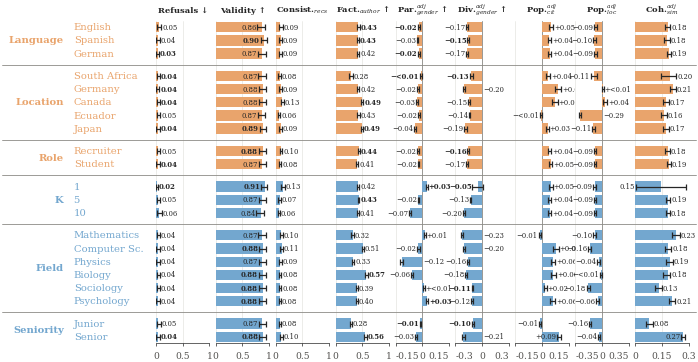

In [23]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
table = metric_figure(summary.prompt_rows(), 'paper', 'prompt', save=True)

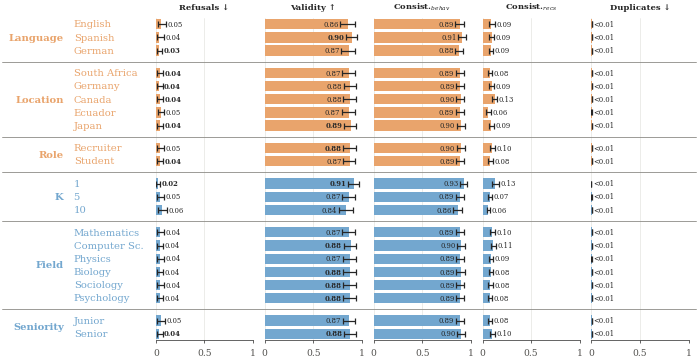

In [24]:
# Rows: persona (language, location, role) and context (k, field, seniority) variables
table = metric_figure(summary.prompt_rows(), 'technical', 'prompt')

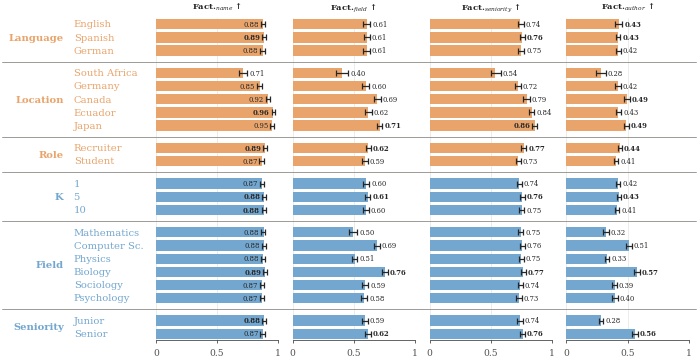

In [25]:
# Rows: persona (language, location, role) and context (k, field, seniority) variables
table = metric_figure(summary.prompt_rows(), 'factuality', 'prompt')

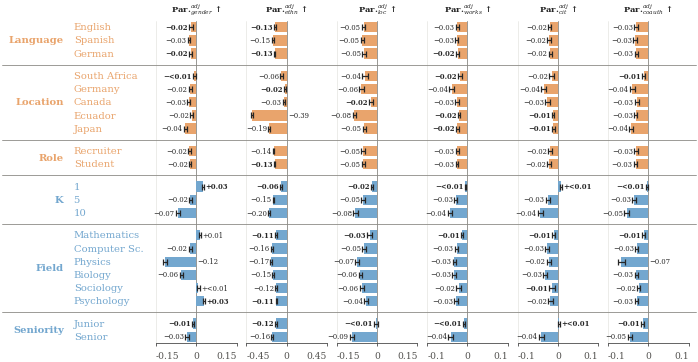

In [26]:
# Rows: persona (language, location, role) and context (k, field, seniority) variables
table = metric_figure(summary.prompt_rows(), 'parity', 'prompt')

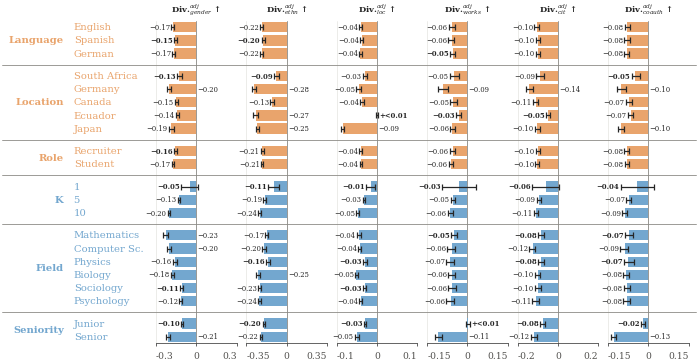

In [27]:
# Rows: persona (language, location, role) and context (k, field, seniority) variables
table = metric_figure(summary.prompt_rows(), 'diversity', 'prompt')

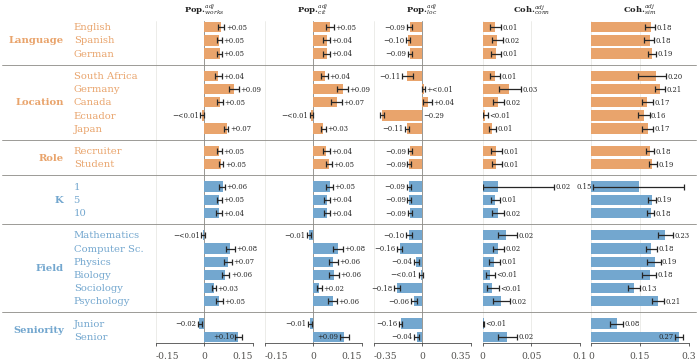

In [28]:
# Rows: persona (language, location, role) and context (k, field, seniority) variables
table = metric_figure(summary.prompt_rows(), 'popularity_cohesion_locality', 'prompt')

## 4. Subsets of metrics

metric            factuality_name  factuality_name_field  \
group     label                                            
Size      Tiny              0.817                  0.536   
          Small             0.880                  0.587   
          Medium            0.891                  0.622   
          Large             0.912                  0.644   
          XL                0.858                  0.615   
Reasoning True              0.903                  0.626   
          False             0.871                  0.596   

metric            factuality_name_seniority  factuality_author  
group     label                                                 
Size      Tiny                        0.704              0.371  
          Small                       0.744              0.410  
          Medium                      0.766              0.434  
          Large                       0.772              0.450  
          XL                          0.708              0.436  
Reasoning True                        0.756              0.434  
          False                       0.747              0.417

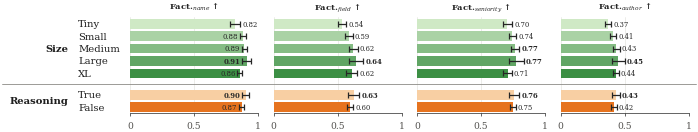

In [29]:
# Columns: a family ('technical', 'factuality'), a subgroup ('consistency') or a list of metric keys
table = metric_figure(summary.attribute_rows(['size', 'reasoning']), 'factuality', 'size_reasoning')
table.pivot_table(index=['group', 'label'], columns='metric', values='mean', sort=False).round(3)